# 07 · Advanced Analytics & Business Insights
Statistical tests, root-cause analysis, an SLA-breach risk model and the resulting insights. **Correlation is not causation**; findings are associations in synthetic data.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 200); pd.set_option("display.float_format", "{:,.2f}".format)
from src.data_cleaning.loader import load_all_processed, load_all_raw
from src.kpi.kpis import kpi_by, compute_all_kpis
from src.analytics import eda
d = load_all_processed()
t, f, o, c = d["tickets_enriched"], d["customer_feedback"], d["operations"], d["customers"]
VIS = ROOT / "visualizations"
def show(*names):
    for n in names: display(Image(filename=str(VIS / f"{n}.png"), width=820))

## Correlations (Spearman)

In [2]:
pd.read_csv(ROOT / "data/reports/stats_correlations.csv")

,relationship,n,spearman_rho,spearman_p,pearson_r,pearson_p,unit,strength
0,First response time vs CSAT,12264,-0.37,0.00,-0.34,0.00,ticket,moderate
1,Resolution time vs CSAT,12301,-0.56,0.00,-0.48,0.00,ticket,strong
2,Agent monthly workload vs avg resolution time,1984,0.14,0.00,0.10,0.00,agent-month,weak
3,Agent monthly workload vs SLA compliance,1976,-0.12,0.00,-0.10,0.00,agent-month,weak
4,Priority (ordinal) vs SLA breach,23211,0.12,0.00,0.12,0.00,ticket,weak
5,Daily transaction volume vs operational cost,1096,0.99,0.00,0.99,0.00,day,strong


## Chi-square tests of independence

In [3]:
pd.read_csv(ROOT / "data/reports/stats_chi_square.csv")

,test,chi2,dof,p_value,cramers_v,min_expected_count,significant_at_0.05
0,Priority x SLA breach,413.52,3,0.00,0.13,433.40,True
1,Channel x SLA breach,"1,546.07",5,0.00,0.26,30.90,True
2,Category x SLA breach,"2,446.64",7,0.00,0.33,256.50,True
3,Channel x Satisfied (CSAT>=4),"1,262.81",5,0.00,0.32,20.10,True
4,Experience level x Reopened,310.99,3,0.00,0.11,221.20,True
5,Customer segment x SLA breach,1.02,3,0.80,0.01,875.40,False


## Group comparisons (Mann-Whitney U primary, Welch t secondary)

In [4]:
pd.read_csv(ROOT / "data/reports/stats_group_tests.csv")

,comparison,n_a,n_b,mean_a,mean_b,median_a,median_b,mann_whitney_p,welch_t_p,rank_biserial
0,CSAT: within SLA vs breached,8431,"3,870.00",4.19,2.79,4.00,3.00,0.00,0.00,0.77
1,Resolution h: Junior vs Senior/Lead agents,2645,"11,598.00",58.83,28.75,37.44,18.37,0.00,0.00,0.33
2,CSAT: real-time (phone/chat) vs async channels,5608,"6,653.00",4.14,3.42,4.00,3.00,0.00,0.00,0.41
3,CSAT: FCR vs non-FCR resolved tickets,2435,"9,866.00",4.47,3.57,5.00,4.00,0.00,0.00,0.52
4,Resolution h: Billing 2025 vs Billing 2024,2029,"1,447.00",49.04,27.28,32.85,19.39,0.00,0.00,0.24
5,Resolution h across 6 channels (Kruskal-Wallis),23211,NaN,NaN,NaN,NaN,NaN,0.00,NaN,NaN


## 95% confidence intervals

In [5]:
display(pd.read_csv(ROOT / "data/reports/stats_csat_ci_by_channel.csv")); display(pd.read_csv(ROOT / "data/reports/stats_sla_ci_by_department.csv"))

,support_channel,n_surveys,avg_csat,ci95_low,ci95_high
0,Phone,2672,4.16,4.13,4.19
1,Live Chat,2936,4.13,4.10,4.16
2,Email,4074,3.47,3.44,3.50
3,Social Media,869,3.37,3.30,3.44
4,Web Portal,1710,3.32,3.27,3.37


,department_name,n_resolved,sla_pct,ci95_low,ci95_high
0,Returns & Refunds,2738,50.00,48.13,51.87
1,Logistics & Delivery,2628,63.85,62.00,65.67
2,Billing & Accounts,4721,73.73,72.46,74.97
3,Technical Support,7880,74.71,73.74,75.66
4,Customer Success,2274,83.07,81.47,84.55
5,Order Management,2970,88.22,87.01,89.33


## Regression: drivers of CSAT (OLS, HC3 robust SE) and SLA breach (logit odds ratios)

In [6]:
print((ROOT / "data/reports/stats_csat_regression.txt").read_text()[:2500])

                            OLS Regression Results                            
Dep. Variable:     satisfaction_score   R-squared:                       0.556
Model:                            OLS   Adj. R-squared:                  0.556
Method:                 Least Squares   F-statistic:                     975.7
Date:                Fri, 30 Oct 2026   Prob (F-statistic):               0.00
Time:                        12:49:56   Log-Likelihood:                -12287.
No. Observations:               12194   AIC:                         2.461e+04
Df Residuals:                   12177   BIC:                         2.473e+04
Df Model:                          16                                         
Covariance Type:                  HC3                                         
                                                                            coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------

In [7]:
pd.read_csv(ROOT / "data/reports/stats_sla_logit_odds_ratios.csv", index_col=0)

,odds_ratio,ci_low,ci_high,p_value
Intercept,0.00,0.00,0.00,0.00
"C(ticket_priority, Treatment('Low'))[T.Critical]",4.24,3.70,4.86,0.00
"C(ticket_priority, Treatment('Low'))[T.High]",1.60,1.46,1.75,0.00
"C(ticket_priority, Treatment('Low'))[T.Medium]",1.28,1.18,1.40,0.00
"C(support_channel, Treatment('Phone'))[T.Email]",4.63,4.19,5.13,0.00
"C(support_channel, Treatment('Phone'))[T.Live Chat]",1.16,1.04,1.31,0.01
"C(support_channel, Treatment('Phone'))[T.Social Media]",4.20,3.64,4.84,0.00
"C(support_channel, Treatment('Phone'))[T.Web Portal]",6.10,5.41,6.87,0.00
"C(ticket_category, Treatment('Product Inquiry'))[T.Account Access]",1.76,1.22,2.55,0.00
"C(ticket_category, Treatment('Product Inquiry'))[T.Billing & Payment]",13.88,10.13,19.01,0.00


## Root-cause analysis: where adverse outcomes concentrate

In [8]:
pd.read_csv(ROOT / "data/reports/rca_top_drivers.csv")

,outcome,factor,level,n,outcome_rate_pct,baseline_pct,lift,excess_cases
0,Escalated,ticket_category,Technical Issue,5437,15.54,10.23,1.52,288
1,Escalated,ticket_priority,High,5853,14.88,10.23,1.45,272
2,Escalated,ticket_priority,Critical,1622,18.87,10.23,1.84,140
3,Escalated,department_name,Technical Support,7971,11.84,10.23,1.16,128
4,Escalated,ticket_category,Complaint,956,23.54,10.23,2.30,127
5,Long resolution (> P90 = 80 h),ticket_priority,Low,6626,18.11,10.00,1.81,537
6,Long resolution (> P90 = 80 h),ticket_category,Returns & Refunds,2738,24.80,10.00,2.48,405
7,Long resolution (> P90 = 80 h),department_name,Returns & Refunds,2738,24.80,10.00,2.48,405
8,Long resolution (> P90 = 80 h),experience_level,Junior,2645,23.48,10.00,2.35,356
9,Long resolution (> P90 = 80 h),support_channel,Email,7617,13.67,10.00,1.37,279


In [9]:
pd.read_csv(ROOT / "data/reports/rca_ops_failure_drivers.csv").head(10)

,factor,level,transactions,failure_rate_pct,lift,excess_failures
0,department_id,DEP-02,3408581,2.77,1.38,26187
1,process_name,Payment Reconciliation,1310492,3.94,1.97,25446
2,operation_type,Refund Processing,310326,8.78,4.39,21048
3,process_name,Refund Approval,310326,8.78,4.39,21048
4,operation_type,Returns Processing,691085,3.19,1.60,8230
5,department_id,DEP-05,691085,3.19,1.60,8230
6,process_name,Returns Inspection,357714,4.21,2.10,7893
7,year,2025,5398394,2.15,1.07,7889
8,process_name,Shipment Dispatch,2024343,2.27,1.14,5525
9,operation_type,Payment Processing,3098255,2.17,1.08,5138


## Predictive model: SLA-breach risk at ticket creation

,cv_roc_auc_mean,cv_roc_auc_std,threshold,test_roc_auc,test_pr_auc,test_precision,test_recall,test_f1
Logistic Regression,0.82,0.00,0.59,0.80,0.63,0.57,0.59,0.58
Gradient Boosting,0.81,0.01,0.54,0.80,0.64,0.56,0.61,0.58


,decile,size,breach_rate_pct
0,1,825,0.73
1,2,825,6.55
2,3,824,11.04
3,4,825,18.30
4,5,825,20.85
5,6,824,33.25
6,7,825,39.52
7,8,824,42.48
8,9,825,54.67
9,10,825,75.27


Excluded (leaky) features: ['first_response_hours', 'reopened_count', 'escalation_flag', 'resolution_type', 'satisfaction_score', 'resolution_hours', 'is_fcr']
Synthetic data. Metrics illustrate methodology only and are not evidence of real-world performance.


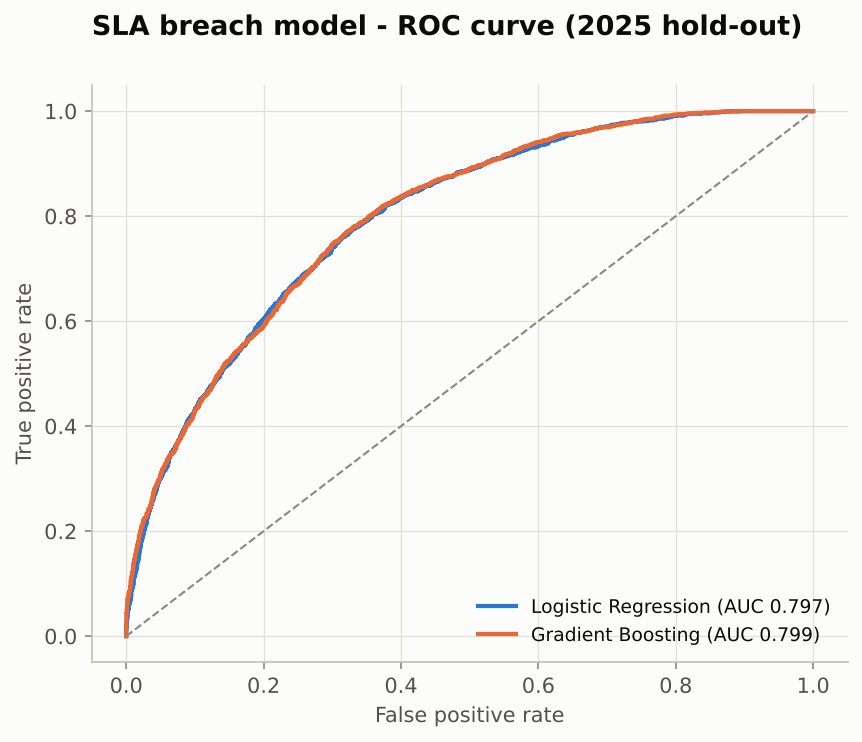

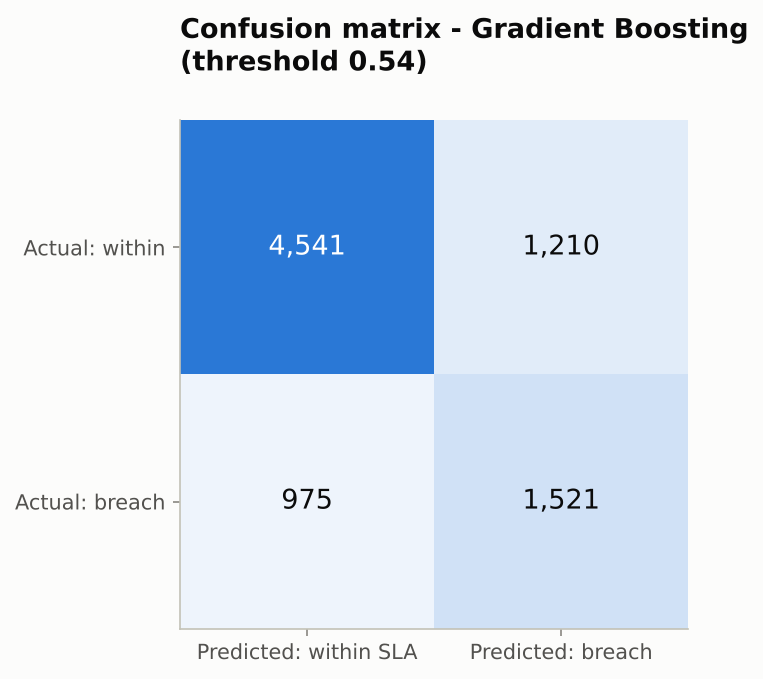

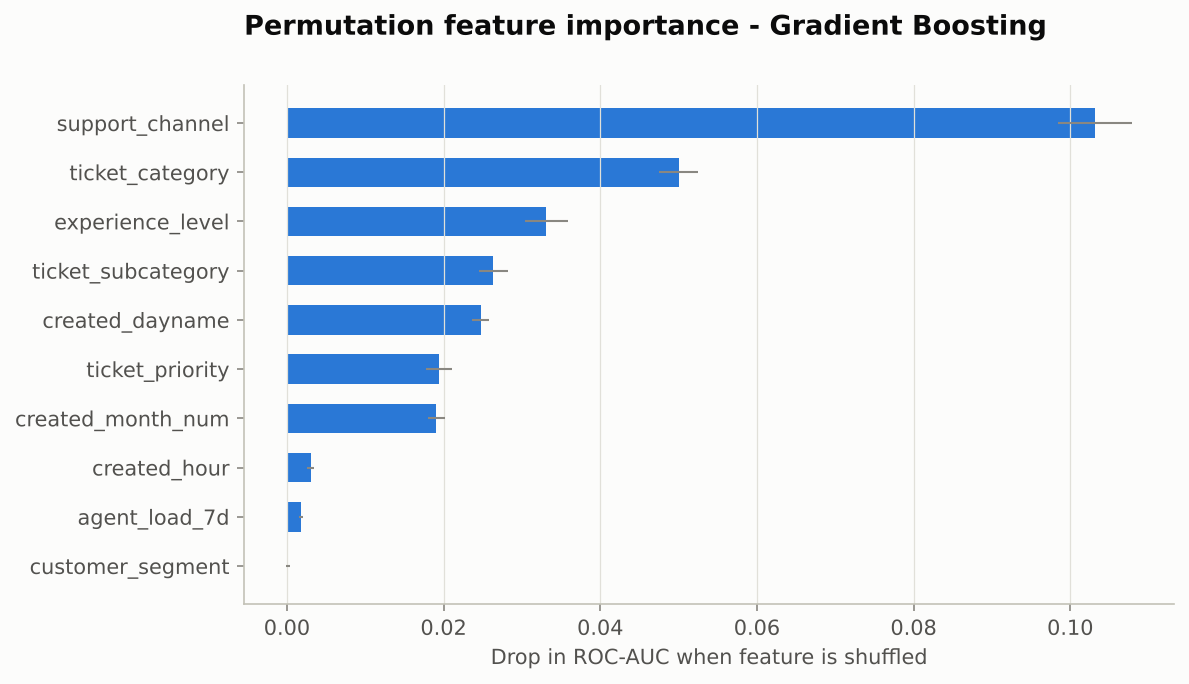

In [10]:
m = __import__("json").loads((ROOT / "data/reports/model_metrics.json").read_text())
display(pd.DataFrame(m["models"]).T.drop(columns="confusion_matrix"))
display(pd.read_csv(ROOT / "data/reports/model_risk_deciles.csv"))
print("Excluded (leaky) features:", m["excluded_leaky_features"]); print(m["caveat"])
show("48_model_roc_curve", "49_model_confusion_matrix", "50_model_feature_importance")

## Generated insights

In [11]:
ins = pd.read_json(ROOT / "data/reports/insights.json")
ins[["id","area","priority","title","finding"]]

,id,area,priority,title,finding
0,1,Customer Support,High,"Asynchronous channels respond in hours, real-t...",Average first response time is 13.47 h on Web ...
1,2,Customer Experience,High,Satisfaction declines steadily as first respon...,Average CSAT is 4.14 when the first response a...
2,3,Customer Experience,High,An SLA breach is the strongest measured driver...,84.3% of customers whose ticket was resolved w...
3,4,SLA & Service Quality,High,Billing & Accounts SLA compliance collapsed in...,Billing SLA compliance fell from 82.86% (2024)...
4,5,Cost,Medium,Billing's outsourcing spend more than doubled ...,"Billing outsourcing cost rose from $53,063 (20..."
5,6,SLA & Service Quality,High,Returns & Refunds has the weakest service perf...,Returns & Refunds resolves only 50.0% of ticke...
6,7,Agent Performance,High,Junior agents breach SLA and get reopened far ...,Junior agents meet SLA on 53.2% of tickets vs ...
7,8,Customer Experience,Medium,First-contact resolution lifts satisfaction by...,Tickets resolved on first contact average CSAT...
8,9,SLA & Service Quality,High,Critical tickets have the lowest SLA compliance,Only 54.7% of Critical tickets are resolved wi...
9,10,SLA & Service Quality,Medium,Most of the open backlog is stale rather than new,"Of 257 open tickets at 31 Dec 2025, 155 (60.3%..."


## Assumptions & limitations
* Tests assume independent observations; tickets from the same customer/agent are not fully independent, so p-values are optimistic. With n in the thousands, focus on **effect sizes** (Cramer's V, rank-biserial, coefficients) rather than p-values.
* CSAT is ordinal; OLS is an interpretable approximation.
* The model is evaluated on a time-based hold-out and uses creation-time features only; metrics are not evidence of real-world performance because the data is synthetic.
* Full narrative: `reports/business_insights.md` and `reports/recommendations.md`.